In [4]:
# 1. Montar o Google Drive
drive.mount('/content/drive')

# 2. Caminho do arquivo no seu Drive
# (Ajuste o caminho caso o arquivo esteja dentro de alguma pasta no Drive)
caminho_drive = '/content/drive/MyDrive/Acidentes_DadosAbertos_20260412.csv'

# 3. Leitura da base de 2.6 GB com tratamento de codificação
try:
    df_renaest = pd.read_csv(caminho_drive, sep=';', encoding='utf-8', low_memory=False)
except UnicodeDecodeError:
    df_renaest = pd.read_csv(caminho_drive, sep=';', encoding='latin1', low_memory=False)

print(f"Dimensão da Base Bruta RENAEST: {df_renaest.shape[0]:,} linhas e {df_renaest.shape[1]} colunas.")

Mounted at /content/drive
Dimensão da Base Bruta RENAEST: 8,371,800 linhas e 35 colunas.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

print("Bibliotecas importadas com sucesso!")
# Exibe todas as colunas em formato de lista
# Exibe cada coluna numerada em uma linha
for i, coluna in enumerate(df_renaest.columns, start=1):
    print(f"{i:02d}. {coluna}")

Bibliotecas importadas com sucesso!
01. num_acidente
02. chv_localidade
03. data_acidente
04. uf_acidente
05. ano_acidente
06. mes_acidente
07. mes_ano_acidente
08. codigo_ibge
09. dia_semana
10. fase_dia
11. tp_acidente
12. cond_meteorologica
13. end_acidente
14. num_end_acidente
15. cep_acidente
16. bairro_acidente
17. km_via_acidente
18. latitude_acidente
19. longitude_acidente
20. hora_acidente
21. tp_rodovia
22. cond_pista
23. tp_cruzamento
24. tp_pavimento
25. tp_curva
26. lim_velocidade
27. tp_pista
28. ind_guardrail
29. ind_cantcentral
30. ind_acostamento
31. qtde_acidente
32. qtde_acid_com_obitos
33. qtde_envolvidos
34. qtde_feridosilesos
35. qtde_obitos


In [6]:
# -------------------------------------------------------------------------
# CÉLULA 3: Filtrar Registros de Minas Gerais (MG)
# -------------------------------------------------------------------------
# Como os atributos textuais/IBGE do município estão truncados no RENAEST-MG,
# carregamos a base estadual para extrair Belo Horizonte via coordenadas GPS na Célula 4.

df_bh = df_renaest[
    df_renaest['uf_acidente'].fillna('').astype(str).str.upper() == 'MG'
].copy()

print(f"Total de registros de Minas Gerais prontos para filtro GPS: {len(df_bh):,} linhas.")

Total de registros de Minas Gerais prontos para filtro GPS: 2,152,175 linhas.


In [7]:
# -------------------------------------------------------------------------
# CÉLULA 3 (Definitiva): Filtragem de Base para Análise de BH - MG
# -------------------------------------------------------------------------

# 1. Filtrar registros do estado de Minas Gerais
df_bh = df_renaest[
    df_renaest['uf_acidente'].fillna('').astype(str).str.upper() == 'MG'
].copy()

# 2. Tenta filtrar pelo nome do município de forma flexível (case-insensitive)
filtro_nome = df_bh['chv_localidade'].astype(str).str.contains('BELO HORIZONTE', case=False, na=False)

if filtro_nome.sum() > 0:
    df_bh = df_bh[filtro_nome].copy()
    print(f"Sucesso: Filtrado por nome do município ('BELO HORIZONTE'): {len(df_bh):,} registros.")
else:
    print(f"Aviso: 'chv_localidade' não possui a string 'BELO HORIZONTE'.")
    print(f"Mantendo os {len(df_bh):,} registros de MG. A Célula 4 isolará BH diretamente pelas coordenadas GPS.")

Aviso: 'chv_localidade' não possui a string 'BELO HORIZONTE'.
Mantendo os 2,152,175 registros de MG. A Célula 4 isolará BH diretamente pelas coordenadas GPS.


In [8]:
# -------------------------------------------------------------------------
# CÉLULA 4: Validar Coordenadas GPS e Isolar Belo Horizonte
# -------------------------------------------------------------------------

col_lat = 'latitude_acidente'
col_lon = 'longitude_acidente'

# 1. Limpeza de texto
lat_str = df_bh[col_lat].astype(str).str.strip().str.replace(',', '.')
lon_str = df_bh[col_lon].astype(str).str.strip().str.replace(',', '.')

# 2. Conversão para numérico
df_bh['lat_temp'] = pd.to_numeric(lat_str, errors='coerce')
df_bh['lon_temp'] = pd.to_numeric(lon_str, errors='coerce')

# 3. Ajuste de escala para inteiros sem ponto decimal (ex: -19812300 -> -19.8123)
for _ in range(7):
    df_bh.loc[df_bh['lat_temp'].abs() > 90, 'lat_temp'] /= 10.0
    df_bh.loc[df_bh['lon_temp'].abs() > 180, 'lon_temp'] /= 10.0

# 4. Filtro por Bounding Box Geográfica de Belo Horizonte (Perímetro Urbano + Região Metropolitana)
# Latitude BH: ~ -19.92 | Longitude BH: ~ -43.94
filtro_bh = (
    df_bh['lat_temp'].between(-20.05, -19.75) &
    df_bh['lon_temp'].between(-44.10, -43.85)
)

# 5. DataFrame final com coordenadas validadas
df_validos = df_bh[filtro_bh].copy()
df_validos[col_lat] = df_validos['lat_temp']
df_validos[col_lon] = df_validos['lon_temp']

# Limpeza de colunas temporárias
df_bh.drop(columns=['lat_temp', 'lon_temp'], inplace=True, errors='ignore')
df_validos.drop(columns=['lat_temp', 'lon_temp'], inplace=True, errors='ignore')

pct_validos = (len(df_validos) / len(df_bh)) * 100 if len(df_bh) > 0 else 0

print(f"Total de ocorrências registradas em MG: {len(df_bh):,}")
print(f"Ocorrências com coordenadas GPS válidas em BH: {len(df_validos):,} ({pct_validos:.2f}% do total de MG)")

if len(df_validos) > 0:
    print("\n--- Amostra de Coordenadas Encontradas em Belo Horizonte ---")
    print(df_validos[[col_lat, col_lon]].head())

Total de ocorrências registradas em MG: 2,152,175
Ocorrências com coordenadas GPS válidas em BH: 476,428 (22.14% do total de MG)

--- Amostra de Coordenadas Encontradas em Belo Horizonte ---
         latitude_acidente  longitude_acidente
1944933         -19.787416          -43.929361
1949645         -19.907566          -43.961459
1951135         -19.901353          -43.905328
1961069         -19.932521          -44.035167
1961256         -19.979071          -43.984213


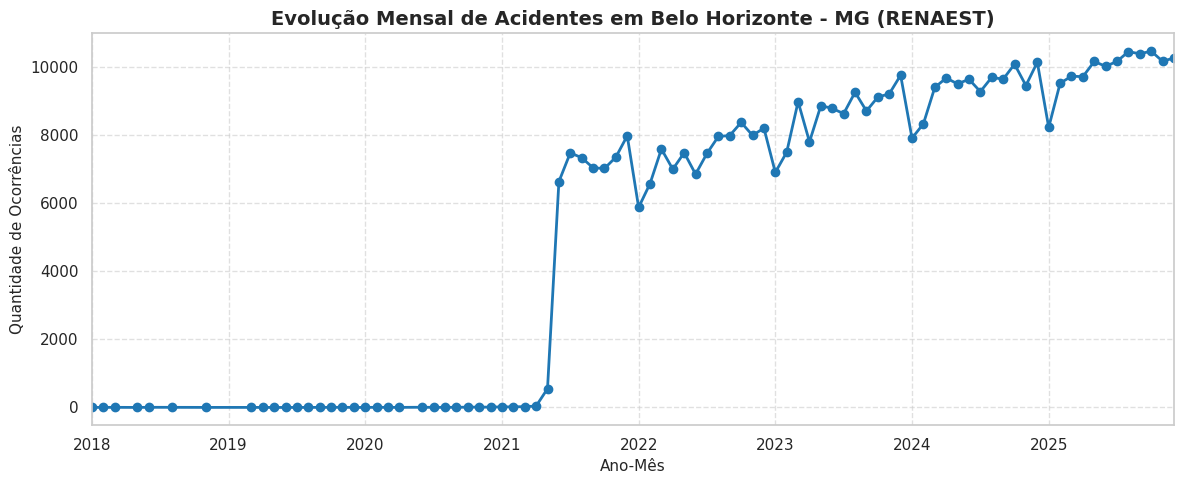


Período coberto: de 2018-01 até 2025-12
Média mensal de acidentes: 5414.0


In [9]:
# -------------------------------------------------------------------------
# CÉLULA 5: Gráfico de Evolução Mensal de Acidentes em Belo Horizonte - MG
# -------------------------------------------------------------------------

col_data = 'data_acidente'

# Utiliza df_validos se houver dados georreferenciados; caso contrário, utiliza df_bh
df_analise = df_validos if 'df_validos' in locals() and len(df_validos) > 0 else df_bh

# Converter coluna de data para datetime
df_analise[col_data] = pd.to_datetime(df_analise[col_data], errors='coerce')

# Agrupar por Mês/Ano
df_analise['ano_mes'] = df_analise[col_data].dt.to_period('M')
contagem_mensal = df_analise['ano_mes'].value_counts().sort_index()

# Verificar se existem datas válidas antes de gerar o gráfico
if len(contagem_mensal) > 0:
    plt.figure(figsize=(12, 5))
    contagem_mensal.plot(kind='line', marker='o', color='#1f77b4', linewidth=2)
    plt.title('Evolução Mensal de Acidentes em Belo Horizonte - MG (RENAEST)', fontsize=14, fontweight='bold')
    plt.xlabel('Ano-Mês', fontsize=11)
    plt.ylabel('Quantidade de Ocorrências', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    print(f"\nPeríodo coberto: de {contagem_mensal.index.min()} até {contagem_mensal.index.max()}")
    print(f"Média mensal de acidentes: {contagem_mensal.mean():.1f}")
else:
    print("Nenhuma data válida foi encontrada no formato esperado.")

In [10]:
# -------------------------------------------------------------------------
# CÉLULA 6: Exportar recorte de Belo Horizonte para o Drive
# -------------------------------------------------------------------------

caminho_saida = '/content/drive/MyDrive/renaest_bh_limpo.csv'
df_validos.to_csv(caminho_saida, index=False, sep=';', encoding='utf-8')

print(f"Dataset de Belo Horizonte salvo com sucesso em: {caminho_saida}")

Dataset de Belo Horizonte salvo com sucesso em: /content/drive/MyDrive/renaest_bh_limpo.csv
